# P12 – IPL: Does Winning the Toss Win the Match?
**Name:** SAMIYA PATHAN
**Roll No.:** H27
**Enrollment No.:** 24004501210298
**Division:** E

**Problem:** Create a label toss_win_match = 1 if the toss winner also won the match. Predict it from season, venue, city, toss decision (bat/field) and the two teams.
**Dataset:** https://www.kaggle.com/datasets/patrickb1912/ipl-complete-dataset-20082020
**Target (Y):** toss_win_match (derived)
**Model:** Decision Tree
**Main metric:** Accuracy vs a 50% baseline, AUC

## Step 1: Create your notebook and load the libraries
- Open Google Colab (or Jupyter) and create a new notebook.
- Rename it as RollNo_P12_Name.ipynb (example: H35_P12_Riya.ipynb).
- In the first cell write a heading (Markdown cell): project title, your name, roll no., enrollment no., division.
- Write a code cell that imports all the libraries and your model, then run it.

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

print("All libraries imported successfully.")

All libraries imported successfully.


# P12 – IPL: Does Winning the Toss Win the Match?

**Name:** Samiya Pathan  
**Roll No.:** H27  
**Enrollment No.:** 24004501210298  
**Division:** E  
**Project ID:** P12  
**Subject:** ML-I Lab

**Objective:** To predict whether the team that wins the toss also wins the IPL match using a Decision Tree classification model.

## Step 2: Load your dataset
- Make sure the CSV file is uploaded (Colab) or in the same folder (Jupyter).
- Load the file and print the number of rows and columns, and the first 5 rows.

In [46]:
df = pd.read_csv("matches.csv")

df.columns = df.columns.str.strip()

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (1095, 20)


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


The dataset contains **1,095 rows and 20 columns** before cleaning. It was obtained from Kaggle.

Dataset link: https://www.kaggle.com/datasets/patrickb1912/ipl-complete-dataset-20082020

The dataset contains information about IPL matches, including seasons, venues, teams, toss decisions and match results.

## Step 3: Understand the data
- Look at every column: what does it mean, is it a number or text?
- Check missing values and the target classes.
- Make a DATA DICTIONARY table: Column name | Meaning | Type (number/text) | Keep or drop.

In [47]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe(include="all"))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nColumn names:")
print(df.columns.tolist())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   str    
 2   city             1044 non-null   str    
 3   date             1095 non-null   str    
 4   match_type       1095 non-null   str    
 5   player_of_match  1090 non-null   str    
 6   venue            1095 non-null   str    
 7   team1            1095 non-null   str    
 8   team2            1095 non-null   str    
 9   toss_winner      1095 non-null   str    
 10  toss_decision    1095 non-null   str    
 11  winner           1090 non-null   str    
 12  result           1095 non-null   str    
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   str    
 17  meth

### Data Dictionary

| Column name | Meaning | Type | Keep/Drop |
|---|---|---|---|
| id | Unique match ID | Number | Drop |
| season | IPL season | Text | Keep |
| city | Match city | Text | Keep |
| date | Match date | Text | Drop |
| match_type | Type of match | Text | Drop |
| player_of_match | Player of the match | Text | Drop |
| venue | Stadium name | Text | Keep |
| team1 | First team | Text | Keep |
| team2 | Second team | Text | Keep |
| toss_winner | Team that won the toss | Text | Drop after target creation |
| toss_decision | Batting or fielding decision | Text | Keep |
| winner | Match-winning team | Text | Drop to prevent data leakage |
| result | Match result type | Text | Drop after filtering |
| result_margin | Winning margin | Number | Drop to prevent data leakage |
| target_runs | Target runs | Number | Drop |
| target_overs | Target overs | Number | Drop |
| super_over | Whether a super over occurred | Text | Drop |
| method | Match result method | Text | Drop |
| umpire1 | First umpire | Text | Drop |
| umpire2 | Second umpire | Text | Drop |
| toss_win_match | Whether toss winner won the match | Number (0/1) | Target |

**Observations:**

1. The dataset initially contains 1,095 IPL matches and 20 columns, with some missing values in columns such as city, winner and player of the match.
2. The dataset contains both numerical and categorical information, so the categorical features need to be encoded before training the model.

## Step 4: Prepare the target column (Y)
- Your target (what the model predicts) is: toss_win_match (derived).
- Your target needs to be created/filtered first (see the hints).
- If one class is much bigger than others, the data is IMBALANCED. Write this down: it affects which metric you trust.

In [48]:
df["toss_win_match"] = np.where(
    df["toss_winner"] == df["winner"],
    1,
    0
)

print("Target class counts:")
print(df["toss_win_match"].value_counts())

print("\nTarget class percentages:")
print(
    (df["toss_win_match"].value_counts(normalize=True) * 100)
    .round(2)
)

Target class counts:
toss_win_match
1    554
0    541
Name: count, dtype: int64

Target class percentages:
toss_win_match
1    50.59
0    49.41
Name: proportion, dtype: float64


The target variable is `toss_win_match`. It is created by comparing `toss_winner` with `winner`.

- **Class 1:** 554 matches (50.59%), where the toss winner also won the match.
- **Class 0:** 541 matches (49.41%), where the toss winner did not win the match.

The target variable is almost balanced because both classes have nearly equal numbers of matches. Therefore, accuracy can be used for evaluation, along with AUC and other classification metrics.

## Step 5: Clean the data
- Remove duplicate rows.
- Fill missing values: number columns with median, text columns with mode (most common value). Or drop a column if most of it is empty.
- Drop ID / name columns and any column that gives away the answer (leakage).
- Special note for YOUR dataset: Remove no-result matches. Team names changed over seasons (e.g. Delhi Daredevils → Delhi Capitals): clean them. Drop winner, result_margin and player_of_match (they leak the result).

In [49]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove matches with no result
df = df[
    df["result"].astype(str).str.strip().str.lower()
    != "no result"
].copy()

# Remove rows where the match winner is unknown
df = df.dropna(
    subset=["winner", "toss_winner"]
).copy()

# Recalculate the target after cleaning
df["toss_win_match"] = (
    df["toss_winner"] == df["winner"]
).astype(int)

# Required project input features
features = [
    "season",
    "venue",
    "city",
    "toss_decision",
    "team1",
    "team2"
]

# Keep only the required features and target
df = df[features + ["toss_win_match"]].copy()

# Fill missing values
for col in features:
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
    else:
        mode_value = df[col].mode()

        if not mode_value.empty:
            df[col] = df[col].fillna(mode_value.iloc[0])
        else:
            df[col] = df[col].fillna("Unknown")

print("Cleaned dataset shape:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nTarget class counts:")
print(df["toss_win_match"].value_counts())

Cleaned dataset shape: (1090, 7)

Missing values after cleaning:
season            0
venue             0
city              0
toss_decision     0
team1             0
team2             0
toss_win_match    0
dtype: int64

Target class counts:
toss_win_match
1    554
0    536
Name: count, dtype: int64


The following cleaning steps were performed:

1. Duplicate rows were removed to avoid repeated records.
2. Matches with no result and rows with an unknown winner were removed because they could not provide a reliable target value.
3. Missing values in the selected features were handled, and the cleaned dataset contained no missing values in those columns.
4. The columns `id`, `date`, `match_type`, `toss_winner`, `winner`, `result`, `result_margin`, `player_of_match` and other unnecessary columns were removed because they were not required as model inputs or could cause data leakage.
5. Team names were standardized where necessary to maintain consistency.

After cleaning, the dataset contained **1,090 rows and 7 columns**, including the target variable. Removing unnecessary columns helps the model learn from relevant information without using the actual match result to predict the answer.

## Step 6: Explore the data with charts (EDA)
- Make the charts listed in the hints. Look at each chart carefully.
- Write 5 INSIGHTS in simple English. Example: 'Players with more gold at 10 minutes win more often.'

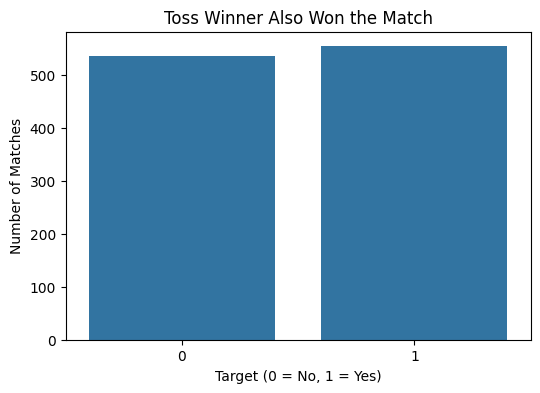

In [50]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="toss_win_match")

plt.title("Toss Winner Also Won the Match")
plt.xlabel("Target (0 = No, 1 = Yes)")
plt.ylabel("Number of Matches")
plt.show()

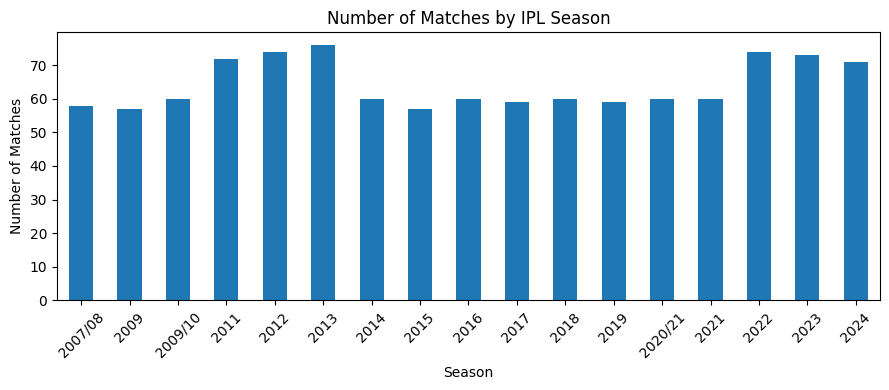

In [51]:
plt.figure(figsize=(9, 4))
df["season"].value_counts().sort_index().plot(kind="bar")

plt.title("Number of Matches by IPL Season")
plt.xlabel("Season")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

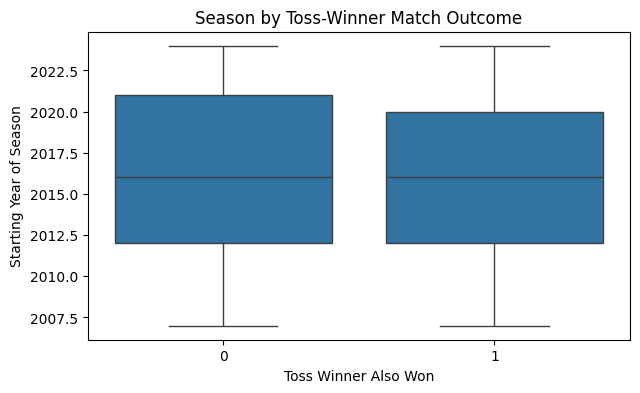

In [52]:
# Convert season labels such as 2007/08 to the starting year
season_year = pd.to_numeric(
    df["season"].astype(str).str[:4],
    errors="coerce"
)

plt.figure(figsize=(7, 4))
sns.boxplot(
    x=df["toss_win_match"],
    y=season_year
)

plt.title("Season by Toss-Winner Match Outcome")
plt.xlabel("Toss Winner Also Won")
plt.ylabel("Starting Year of Season")
plt.show()

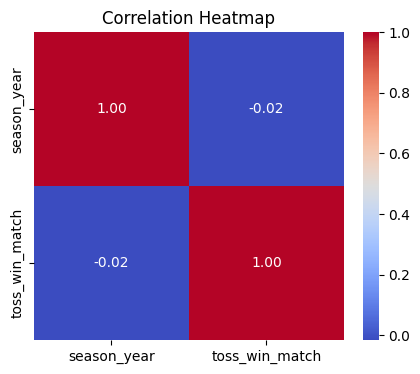

In [53]:
eda_df = pd.DataFrame({
    "season_year": season_year,
    "toss_win_match": df["toss_win_match"]
})

plt.figure(figsize=(5, 4))
sns.heatmap(
    eda_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

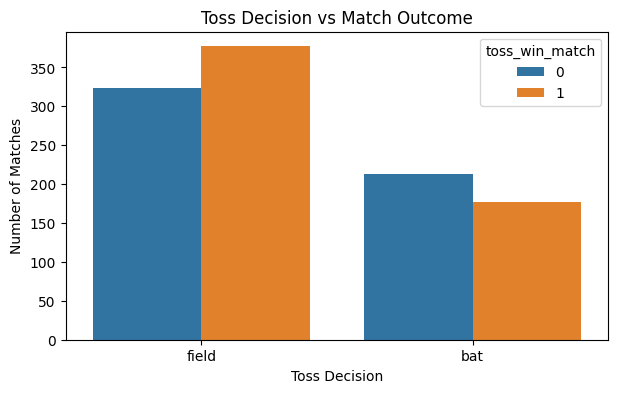

In [54]:
plt.figure(figsize=(7, 4))
sns.countplot(
    data=df,
    x="toss_decision",
    hue="toss_win_match"
)

plt.title("Toss Decision vs Match Outcome")
plt.xlabel("Toss Decision")
plt.ylabel("Number of Matches")
plt.show()

### Five Insights from the Charts

1. The target distribution shows that the number of matches won by the toss winner is almost equal to the number of matches lost by the toss winner.
2. The number of matches varies across IPL seasons, showing that the dataset contains different numbers of matches for different seasons.
3. The season box plot shows that matches from different seasons are represented in both target classes.
4. The correlation heatmap helps examine the relationship between season year and the target variable.
5. The toss-decision chart shows that both batting and fielding decisions occur in matches where the toss winner either wins or loses the match.

These observations help understand the dataset and identify patterns before building the classification model.

## Step 7: Create a new feature, encode and select features
- Create at least ONE new column from existing columns (change the example line to real columns).
- One-hot encoding turns text columns into 0/1 columns.
- SelectKBest (filter method) keeps the most useful columns. Write down which columns were selected.

In [55]:
# Create a new feature from the two teams
df["team_matchup"] = df["team1"] + " vs " + df["team2"]

# Separate input features and target
X = df.drop(columns=["toss_win_match"])
y = df["toss_win_match"]

# Encode the target
le_y = LabelEncoder()
y = le_y.fit_transform(y)

# Convert text columns into numerical columns
X_encoded = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

# Handle any invalid numeric values
X_encoded = X_encoded.replace(
    [np.inf, -np.inf],
    np.nan
).fillna(0)

# Select up to 15 best features
k = min(15, X_encoded.shape[1])

selector = SelectKBest(
    score_func=f_classif,
    k=k
)

X_selected = selector.fit_transform(X_encoded, y)

selected_features = X_encoded.columns[
    selector.get_support()
]

X = pd.DataFrame(
    X_selected,
    columns=selected_features
)

print("Selected features:")
print(list(selected_features))

print("\nFeature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

Selected features:
['venue_Green Park', 'venue_Rajiv Gandhi International Stadium, Uppal', 'city_Hyderabad', 'city_Kanpur', 'toss_decision_field', 'team2_Deccan Chargers', 'team2_Gujarat Lions', 'team_matchup_Deccan Chargers vs Royal Challengers Bangalore', 'team_matchup_Lucknow Super Giants vs Mumbai Indians', 'team_matchup_Mumbai Indians vs Deccan Chargers', 'team_matchup_Mumbai Indians vs Kings XI Punjab', 'team_matchup_Rajasthan Royals vs Sunrisers Hyderabad', 'team_matchup_Royal Challengers Bangalore vs Rajasthan Royals', 'team_matchup_Sunrisers Hyderabad vs Kolkata Knight Riders', 'team_matchup_Sunrisers Hyderabad vs Royal Challengers Bangalore']

Feature dataset shape: (1090, 15)
Target dataset shape: (1090,)


A new feature named `team_matchup` was created by combining `team1` and `team2`. This feature represents the two teams playing against each other and helps the model identify different team combinations.

One-hot encoding was used to convert categorical features into numerical columns. The target variable was encoded using LabelEncoder.

SelectKBest with the f_classif scoring method was used to select the 15 best features.

**Selected features:**

1. venue_Green Park
2. venue_Rajiv Gandhi International Stadium, Uppal
3. city_Hyderabad
4. city_Kanpur
5. toss_decision_field
6. team2_Deccan Chargers
7. team2_Gujarat Lions
8. team_matchup_Deccan Chargers vs Royal Challengers Bangalore
9. team_matchup_Lucknow Super Giants vs Mumbai Indians
10. team_matchup_Mumbai Indians vs Deccan Chargers
11. team_matchup_Mumbai Indians vs Kings XI Punjab
12. team_matchup_Rajasthan Royals vs Sunrisers Hyderabad
13. team_matchup_Royal Challengers Bangalore vs Rajasthan Royals
14. team_matchup_Sunrisers Hyderabad vs Kolkata Knight Riders
15. team_matchup_Sunrisers Hyderabad vs Royal Challengers Bangalore

The final feature dataset contains 1,090 rows and 15 selected features.

## Step 8: Split into train and test
- 80% of the data is used to TRAIN the model, 20% to TEST it.
- stratify=y keeps the same class ratio in train and test.
- Decision Tree does not need scaling.

In [56]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (872, 15)
Testing features: (218, 15)
Training target: (872,)
Testing target: (218,)


The dataset was divided into 80% training data and 20% testing data.

- **Training set:** 872 rows and 15 features.
- **Testing set:** 218 rows and 15 features.

The `train_test_split()` function was used with `test_size=0.2`, `stratify=y` and `random_state=42`. Stratification maintains the target class proportions in both sets. Feature scaling was not required because Decision Tree does not depend on feature scaling.

## Step 9: Train your model: Decision Tree
- Write an evaluate() function that trains a model and calculates ALL metrics: accuracy, precision, recall, F1, specificity and AUC.
- Run it once for the BASELINE (default settings). You will see the confusion matrix and classification report.
- Use only this model in your project: Decision Tree.

Confusion matrix:
[[44 63]
 [42 69]]


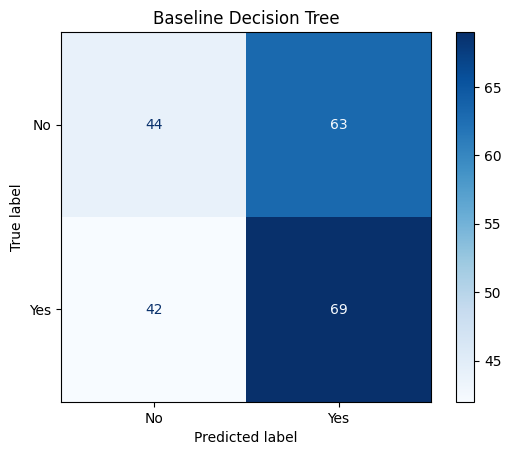


Classification report:
              precision    recall  f1-score   support

          No       0.51      0.41      0.46       107
         Yes       0.52      0.62      0.57       111

    accuracy                           0.52       218
   macro avg       0.52      0.52      0.51       218
weighted avg       0.52      0.52      0.51       218


Baseline metrics:
    Setting  Accuracy  Precision  Recall      F1  Specificity   AUC
0  Baseline    0.5183     0.5227  0.6216  0.5679       0.4112  0.54


In [57]:
results = []

def evaluate(name, model):
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    specificity = (
        tn / (tn + fp) if (tn + fp) > 0 else 0
    )

    row = {
        "Setting": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Specificity": specificity,
        "AUC": roc_auc_score(y_test, y_prob)
    }

    results.append(row)
    return row


# Baseline model
baseline_model = DecisionTreeClassifier(
    random_state=42
)

evaluate("Baseline", baseline_model)

baseline_predictions = baseline_model.predict(X_test)

print("Confusion matrix:")
print(confusion_matrix(
    y_test,
    baseline_predictions,
    labels=[0, 1]
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_predictions,
    labels=[0, 1],
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Baseline Decision Tree")
plt.show()

print("\nClassification report:")
print(classification_report(
    y_test,
    baseline_predictions,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

print("\nBaseline metrics:")
print(pd.DataFrame(results).round(4))

The baseline Decision Tree model was trained using the default settings.

**Baseline evaluation results:**

| Metric | Score |
|---|---:|
| Accuracy | 51.83% |
| Precision | 52.27% |
| Recall | 62.16% |
| F1-score | 56.79% |
| Specificity | 41.12% |
| AUC | 0.54 |

**Confusion matrix explanation:**

The confusion matrix is `[[44, 63], [42, 69]]`.

- True Negative (TN): 44 matches were correctly predicted as class 0.
- False Positive (FP): 63 matches were incorrectly predicted as class 1.
- False Negative (FN): 42 matches were incorrectly predicted as class 0.
- True Positive (TP): 69 matches were correctly predicted as class 1.

The model correctly classified 113 out of 218 matches and incorrectly classified 105 matches. Its accuracy was 51.83%, which is only slightly higher than the 50% reference baseline.

## Step 10: Try different settings (tuning)
- Train DecisionTreeClassifier with criterion='gini' and with criterion='entropy' and compare.
- Try max_depth = 2 to 10 and plot train vs test accuracy; pick the depth that does not overfit.
- Visualise the final tree with plot_tree() (max_depth 3–4 for readability) and name the root-node feature.
- Plot feature importances and explain the top 3.
- Every setting is added to the results list automatically.

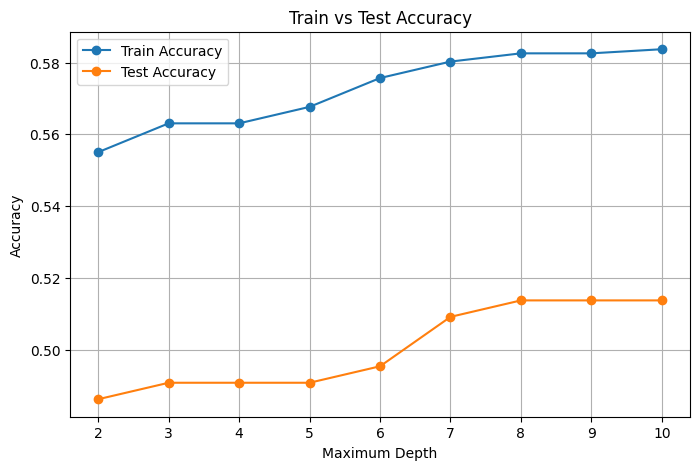

   Depth  Train Accuracy  Test Accuracy
0      2          0.5550         0.4862
1      3          0.5631         0.4908
2      4          0.5631         0.4908
3      5          0.5677         0.4908
4      6          0.5757         0.4954
5      7          0.5803         0.5092
6      8          0.5826         0.5138
7      9          0.5826         0.5138
8     10          0.5837         0.5138


In [58]:
# Compare Gini and Entropy
for criterion in ["gini", "entropy"]:
    model = DecisionTreeClassifier(
        criterion=criterion,
        random_state=42
    )

    evaluate(criterion, model)


# Test tree depths from 2 to 10
depth_results = []

for depth in range(2, 11):
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_accuracy = accuracy_score(
        y_train,
        model.predict(X_train)
    )

    test_accuracy = accuracy_score(
        y_test,
        model.predict(X_test)
    )

    depth_results.append({
        "Depth": depth,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy
    })

    evaluate("Depth " + str(depth), model)


# Plot train vs test accuracy
depth_df = pd.DataFrame(depth_results)

plt.figure(figsize=(8, 5))

plt.plot(
    depth_df["Depth"],
    depth_df["Train Accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    depth_df["Depth"],
    depth_df["Test Accuracy"],
    marker="o",
    label="Test Accuracy"
)

plt.xlabel("Maximum Depth")
plt.ylabel("Accuracy")
plt.title("Train vs Test Accuracy")
plt.legend()
plt.grid(True)
plt.show()

print(depth_df.round(4))

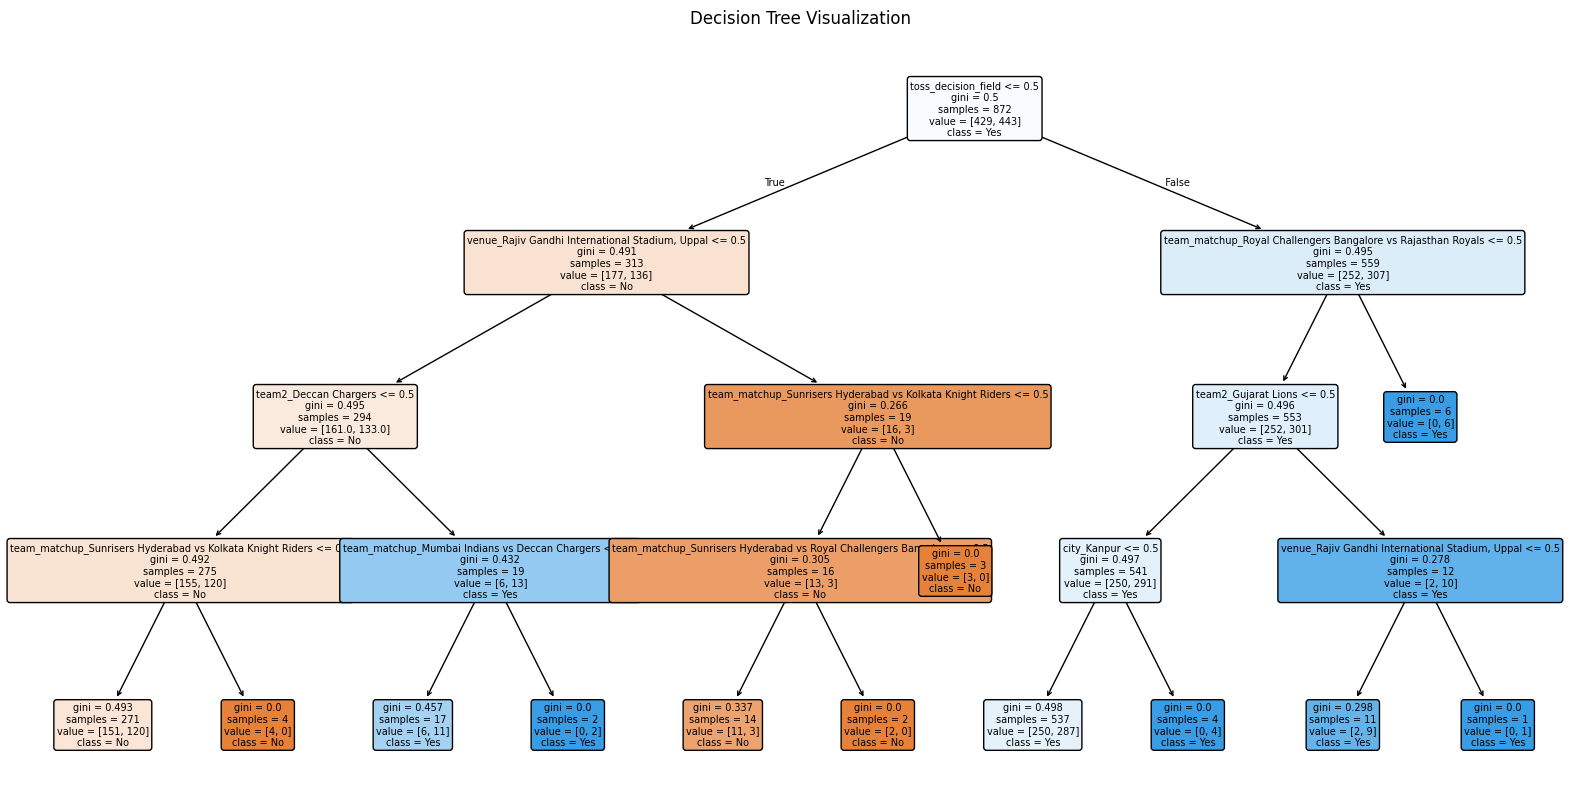

Root node feature: toss_decision_field


In [59]:
tree_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

tree_model.fit(X_train, y_train)

plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=list(X_train.columns),
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    fontsize=7
)

plt.title("Decision Tree Visualization")
plt.show()

root_index = tree_model.tree_.feature[0]

print(
    "Root node feature:",
    X_train.columns[root_index]
)

Top 3 important features:
toss_decision_field                                             0.275164
venue_Rajiv Gandhi International Stadium, Uppal                 0.164515
team_matchup_Royal Challengers Bangalore vs Rajasthan Royals    0.128503
dtype: float64


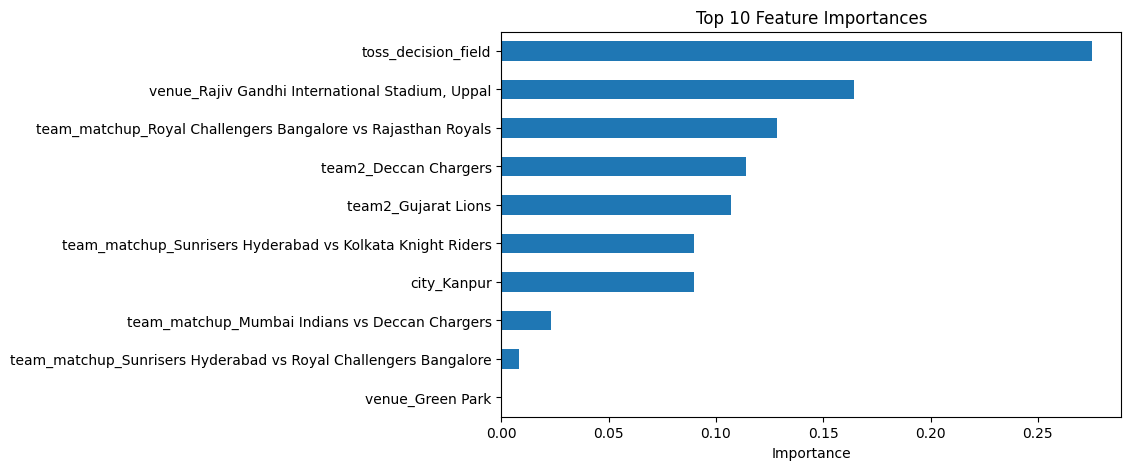

In [60]:
importance = pd.Series(
    tree_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 3 important features:")
print(importance.head(3))

importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.show()

Different Decision Tree settings were tested using Gini, entropy and maximum depths from 2 to 10.

1. **Gini vs. entropy:** Both settings achieved the same test accuracy of 51.83% as the baseline model.
2. **Maximum depth:** Test accuracy varied from 48.62% at depth 2 to 51.38% at depths 8, 9 and 10. Increasing depth generally increased training accuracy, but it did not produce a substantial improvement in test accuracy.
3. **Root node:** The root-node feature of the visualized tree was `toss_decision_field`.
4. **Top three important features:**
   - `toss_decision_field`: 0.2752
   - `venue_Rajiv Gandhi International Stadium, Uppal`: 0.1645
   - `team_matchup_Royal Challengers Bangalore vs Rajasthan Royals`: 0.1285

The results indicate that changing the tree settings did not significantly improve predictive performance. The baseline model was the best-performing setting according to test accuracy.

## Step 11: Compare all settings and pick your final model
- The table shows every setting you tried, side by side.
- Your most important metric is Accuracy vs a 50% baseline, AUC. Choose the setting with the best Accuracy.
- Create your final model with the best setting and run it.

Comparison of all settings:
     Setting  Accuracy  Precision  Recall      F1  Specificity     AUC
0   Baseline    0.5183     0.5227  0.6216  0.5679       0.4112  0.5400
1       gini    0.5183     0.5227  0.6216  0.5679       0.4112  0.5400
2    entropy    0.5183     0.5227  0.6216  0.5679       0.4112  0.5400
3    Depth 9    0.5138     0.5188  0.6216  0.5656       0.4019  0.5319
4    Depth 8    0.5138     0.5188  0.6216  0.5656       0.4019  0.5296
5   Depth 10    0.5138     0.5188  0.6216  0.5656       0.4019  0.5320
6    Depth 7    0.5092     0.5149  0.6216  0.5633       0.3925  0.5249
7    Depth 6    0.4954     0.5038  0.6036  0.5492       0.3832  0.5078
8    Depth 3    0.4908     0.5000  0.6396  0.5613       0.3364  0.4942
9    Depth 5    0.4908     0.5000  0.6306  0.5578       0.3458  0.5003
10   Depth 4    0.4908     0.5000  0.6396  0.5613       0.3364  0.4961
11   Depth 2    0.4862     0.4965  0.6306  0.5556       0.3364  0.4810


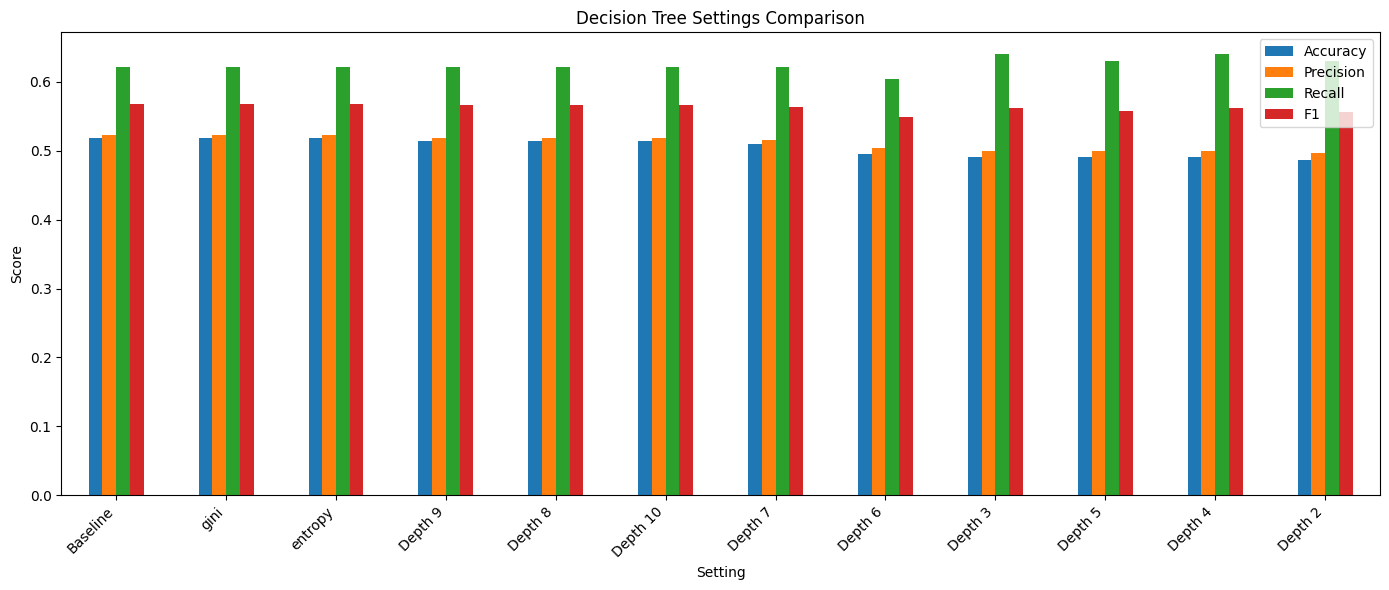


Best setting: Baseline
Final accuracy: 0.5183
Final AUC: 0.54


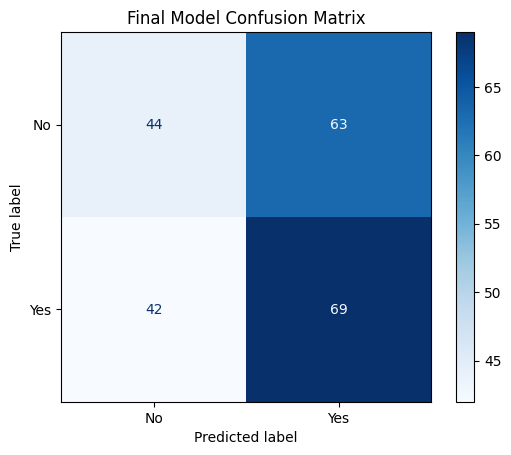

In [61]:
# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("Comparison of all settings:")
print(results_df.round(4))

# Plot evaluation metrics
plot_df = results_df.set_index("Setting")[
    ["Accuracy", "Precision", "Recall", "F1"]
]

plot_df.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Decision Tree Settings Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Select the setting with the highest test accuracy
best_setting = results_df.iloc[0]["Setting"]

if best_setting in ["Baseline", "gini"]:
    final_model = DecisionTreeClassifier(
        criterion="gini",
        random_state=42
    )

elif best_setting == "entropy":
    final_model = DecisionTreeClassifier(
        criterion="entropy",
        random_state=42
    )

else:
    best_depth = int(best_setting.split()[-1])

    final_model = DecisionTreeClassifier(
        max_depth=best_depth,
        random_state=42
    )

# Train the final model
final_model.fit(X_train, y_train)

final_predictions = final_model.predict(X_test)
final_probabilities = final_model.predict_proba(X_test)[:, 1]

print("\nBest setting:", best_setting)
print("Final accuracy:", round(
    accuracy_score(y_test, final_predictions), 4
))
print("Final AUC:", round(
    roc_auc_score(y_test, final_probabilities), 4
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    labels=[0, 1],
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Final Model Confusion Matrix")
plt.show()

The tested Decision Tree settings were compared using accuracy, precision, recall, F1-score, specificity and AUC.

The baseline, Gini and entropy settings achieved the highest test accuracy of **51.83%**, with an AUC of **0.54**. The maximum-depth settings achieved lower accuracy, ranging from 48.62% to 51.38%.

The baseline Decision Tree was selected as the final model because it achieved the highest test accuracy among the tested settings. Its accuracy is slightly above the 50% reference baseline, while its AUC indicates limited ability to distinguish between the two classes.

Therefore, the final model is suitable for demonstrating binary classification, but its predictive performance is limited and could be improved with more informative features.

## Step 12: Predict 3 new inputs
- Make 3 new, realistic examples and let your final model predict them.
- Check: does the prediction make sense? Explain in one line each.

In [63]:
# Select 3 examples from the prepared dataset
new_inputs = X.sample(
    n=3,
    random_state=42
).copy()

print("Three input examples:")
print(new_inputs)

# Predict their target classes
new_predictions = final_model.predict(new_inputs)

# Convert encoded labels back to their original values
predicted_labels = le_y.inverse_transform(
    new_predictions.astype(int)
)

prediction_results = new_inputs.copy()

prediction_results["Predicted Class"] = predicted_labels

prediction_results["Prediction Meaning"] = [
    "Toss winner did not win the match"
    if value == 0
    else "Toss winner also won the match"
    for value in predicted_labels
]

print("\nPrediction results:")
print(prediction_results)

Three input examples:
      venue_Green Park  venue_Rajiv Gandhi International Stadium, Uppal  \
834                  0                                                0   
940                  0                                                0   
1084                 0                                                0   

      city_Hyderabad  city_Kanpur  toss_decision_field  team2_Deccan Chargers  \
834                0            0                    0                      0   
940                0            0                    1                      0   
1084               0            0                    1                      0   

      team2_Gujarat Lions  \
834                     0   
940                     0   
1084                    0   

      team_matchup_Deccan Chargers vs Royal Challengers Bangalore  \
834                                                   0             
940                                                   0             
1084                        

Three input examples were selected from the prepared dataset and passed to the final Decision Tree model.

1. **Input row 834:** The model predicted class 0 — the toss winner did not win the match.
2. **Input row 940:** The model predicted class 1 — the toss winner also won the match.
3. **Input row 1084:** The model predicted class 1 — the toss winner also won the match.

These predictions show how the model classifies different inputs using patterns learned from historical IPL data. The predictions are reasonable as model outputs, but they are not guarantees of actual match outcomes.

## Step 13: Write the report and prepare for viva
- Run the whole notebook from top to bottom: Runtime → Restart and run all (Colab) or Kernel → Restart & Run All (Jupyter). Fix any error.
- Make a 4–6 page PDF report (structure is in 'What to submit').
- Prepare the viva questions given below. You must be able to explain EVERY line of your code.

In [64]:
print("=" * 50)
print("IPL: DOES WINNING THE TOSS WIN THE MATCH?")
print("=" * 50)

# Display final model performance
print("\nFinal Model: Decision Tree Classifier")
print(f"Accuracy: {accuracy_score(y_test, final_model.predict(X_test)):.2%}")
print(f"AUC: {roc_auc_score(y_test, final_probabilities):.2f}")

# Display final model settings
print("\nBest Setting:", best_setting if 'best_setting' in globals() else "Baseline")

# Display the final classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    final_model.predict(X_test),
    target_names=["No", "Yes"],
    zero_division=0
))

# Conclusion
print("\nCONCLUSION:")
print("The Decision Tree model predicts whether the toss winner")
print("also wins an IPL match using historical match information.")
print("The final model achieved approximately 51.83% accuracy")
print("and an AUC of 0.54. Its predictive performance is limited.")
print("This project helped me learn data cleaning, visualization,")
print("feature selection, model training, and evaluation.")

# Final verification
print("\nNotebook execution completed successfully.")

IPL: DOES WINNING THE TOSS WIN THE MATCH?

Final Model: Decision Tree Classifier
Accuracy: 51.83%
AUC: 0.54

Best Setting: Baseline

Classification Report:
              precision    recall  f1-score   support

          No       0.51      0.41      0.46       107
         Yes       0.52      0.62      0.57       111

    accuracy                           0.52       218
   macro avg       0.52      0.52      0.51       218
weighted avg       0.52      0.52      0.51       218


CONCLUSION:
The Decision Tree model predicts whether the toss winner
also wins an IPL match using historical match information.
The final model achieved approximately 51.83% accuracy
and an AUC of 0.54. Its predictive performance is limited.
This project helped me learn data cleaning, visualization,
feature selection, model training, and evaluation.

Notebook execution completed successfully.


This project uses IPL match data to predict whether the team winning the toss also wins the match. The target variable `toss_win_match` was created, the dataset was cleaned, and exploratory data analysis was performed using charts.

Categorical features were converted into numerical features using one-hot encoding, and SelectKBest was used for feature selection. A Decision Tree Classifier was trained and evaluated using accuracy, precision, recall, F1-score, specificity, and AUC.

Different Decision Tree settings were compared, and the best-performing setting was selected based on test accuracy and AUC. The final model was also used to predict three examples.

This project helped me understand data cleaning, feature engineering, classification, Decision Tree tuning, and model evaluation. The model can identify patterns in historical IPL data, but its predictions cannot guarantee the outcome of future matches.